# 07 · Evaluation and the locked threshold

**Why.** Choose a screening cutoff on training data, lock it, and only then score the held-out test set, exactly once. The target, set in advance: flag at least 80% of people with the condition, at the lowest false-alarm cost.

**Re-run it.** `threshold` reads training rows only and writes `threshold.json`; `test` refuses to run unless that file matches the split and the model file.

```bash
diabetes-screening-model threshold --input data/derived/combined_BRFSS2015.csv \
  --provenance data/derived/combined_BRFSS2015.provenance.json --split reports/modeling/combined/split \
  --training reports/modeling/combined/training --output reports/modeling/combined/threshold
diabetes-screening-model test --input data/derived/combined_BRFSS2015.csv \
  --provenance data/derived/combined_BRFSS2015.provenance.json --split reports/modeling/combined/split \
  --training reports/modeling/combined/training --threshold reports/modeling/combined/threshold \
  --source data/raw/archive.zip --output reports/modeling/combined/evaluation
```

In [1]:
# Every notebook reads the committed aggregate reports, so it runs from a fresh clone without the survey data.
from pathlib import Path
import json

import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
ENDPOINT = "combined"  # "prediabetes" shows the sensitivity analysis instead
REPORTS = ROOT / "reports"
STAGE_1_4 = REPORTS / ("uploaded-combined" if ENDPOINT == "combined" else "prediabetes")
MODELING = REPORTS / "modeling" / ENDPOINT
pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 100)


def read_json(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))


def figure(path, width=860):
    display(Image(filename=str(path), width=width))

## The locked cutoff (training rows only)

In [2]:
threshold = read_json(MODELING / "threshold" / "threshold.json")
print(f"Model: {threshold['model']}; cutoff {threshold['threshold']:.4f}; target recall {threshold['target_recall']:.0%}")
print("Rule:", threshold["rule"])
print("Recalibration:", threshold["recalibration"] or "not needed")
pd.read_csv(MODELING / "threshold" / "operating_points.csv")[
    ["rule", "locked", "threshold", "recall", "precision", "specificity", "flagged_per_1000"]]

Model: xgboost; cutoff 0.1530; target recall 80%
Rule: The highest cutoff on the selected model's out-of-fold predicted risks (training rows only) that still flags at least 80% of the training cases. The highest such cutoff flags the fewest people, so it is the cheapest way to meet the target. Fixed before any test row is read.
Recalibration: not needed


,rule,locked,threshold,recall,precision,specificity,flagged_per_1000
0,catch 70% of cases,False,0.209,0.700,0.375,0.782,293.953
1,catch 75% of cases,False,0.181,0.750,0.353,0.743,334.363
2,catch 80% of cases,True,0.153,0.800,0.332,0.698,380.223
3,catch 85% of cases,False,0.122,0.850,0.306,0.639,437.815
4,catch 90% of cases,False,0.090,0.900,0.278,0.563,509.673
5,best F2,False,0.125,0.846,0.308,0.645,432.435


## Final results on the locked test set

95% bootstrap intervals (1,000 resamples, cutoff held fixed). Logistic regression and the checklist are context only.

In [3]:
results = pd.read_csv(MODELING / "evaluation" / "test_results.csv")
table = results[["model", "threshold"]].copy()
for metric in ["recall", "precision", "specificity", "f2", "pr_auc", "roc_auc"]:
    table[metric] = [f"{r[metric]:.3f} ({r[metric + '_ci_low']:.3f}-{r[metric + '_ci_high']:.3f})"
                     for _, r in results.iterrows()]
table

,model,threshold,recall,precision,specificity,f2,pr_auc,roc_auc
0,xgboost,0.153,0.794 (0.785-0.803),0.333 (0.326-0.339),0.702 (0.698-0.707),0.622 (0.614-0.629),0.465 (0.454-0.476),0.826 (0.821-0.830)
1,logistic_regression,0.143,0.794 (0.785-0.803),0.324 (0.317-0.331),0.690 (0.686-0.694),0.615 (0.608-0.623),0.442 (0.431-0.453),0.819 (0.814-0.824)
2,ada_checklist,0.500,0.800 (0.791-0.809),0.267 (0.261-0.272),0.589 (0.584-0.593),0.571 (0.564-0.579),0.325 (0.317-0.334),0.756 (0.750-0.761)


## Per 1,000 people screened

In [4]:
results.set_index("model")[["flagged_per_1000", "cases_per_1000", "cases_found_per_1000", "cases_missed_per_1000",
                            "false_alarms_per_1000", "precision"]].round(1)

,flagged_per_1000,cases_per_1000,cases_found_per_1000,cases_missed_per_1000,false_alarms_per_1000,precision
model,,,,,,
xgboost,375.8,157.6,125.1,32.5,250.7,0.3
logistic_regression,386.2,157.6,125.1,32.5,261.1,0.3
ada_checklist,472.6,157.6,126.0,31.5,346.5,0.3


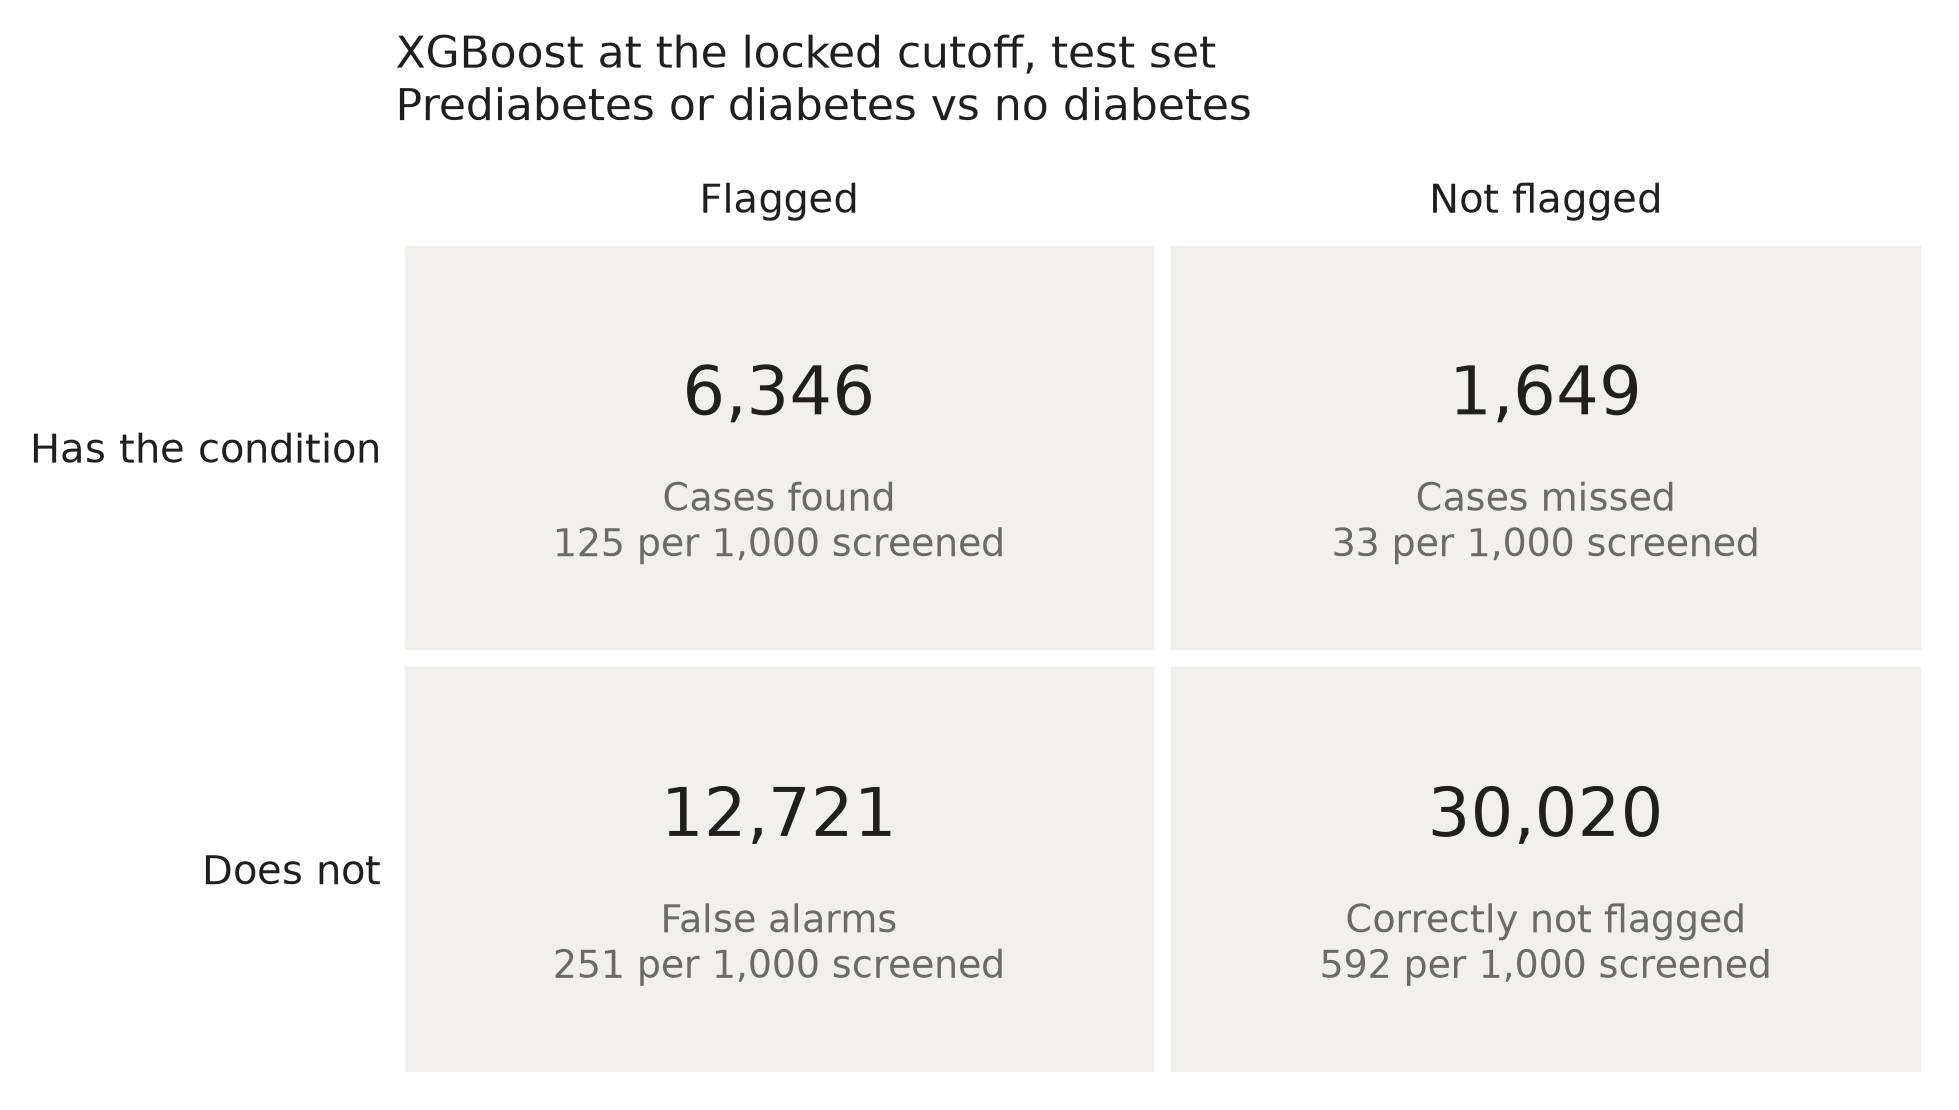

In [5]:
figure(MODELING / "evaluation" / "confusion_matrix.png", width=600)

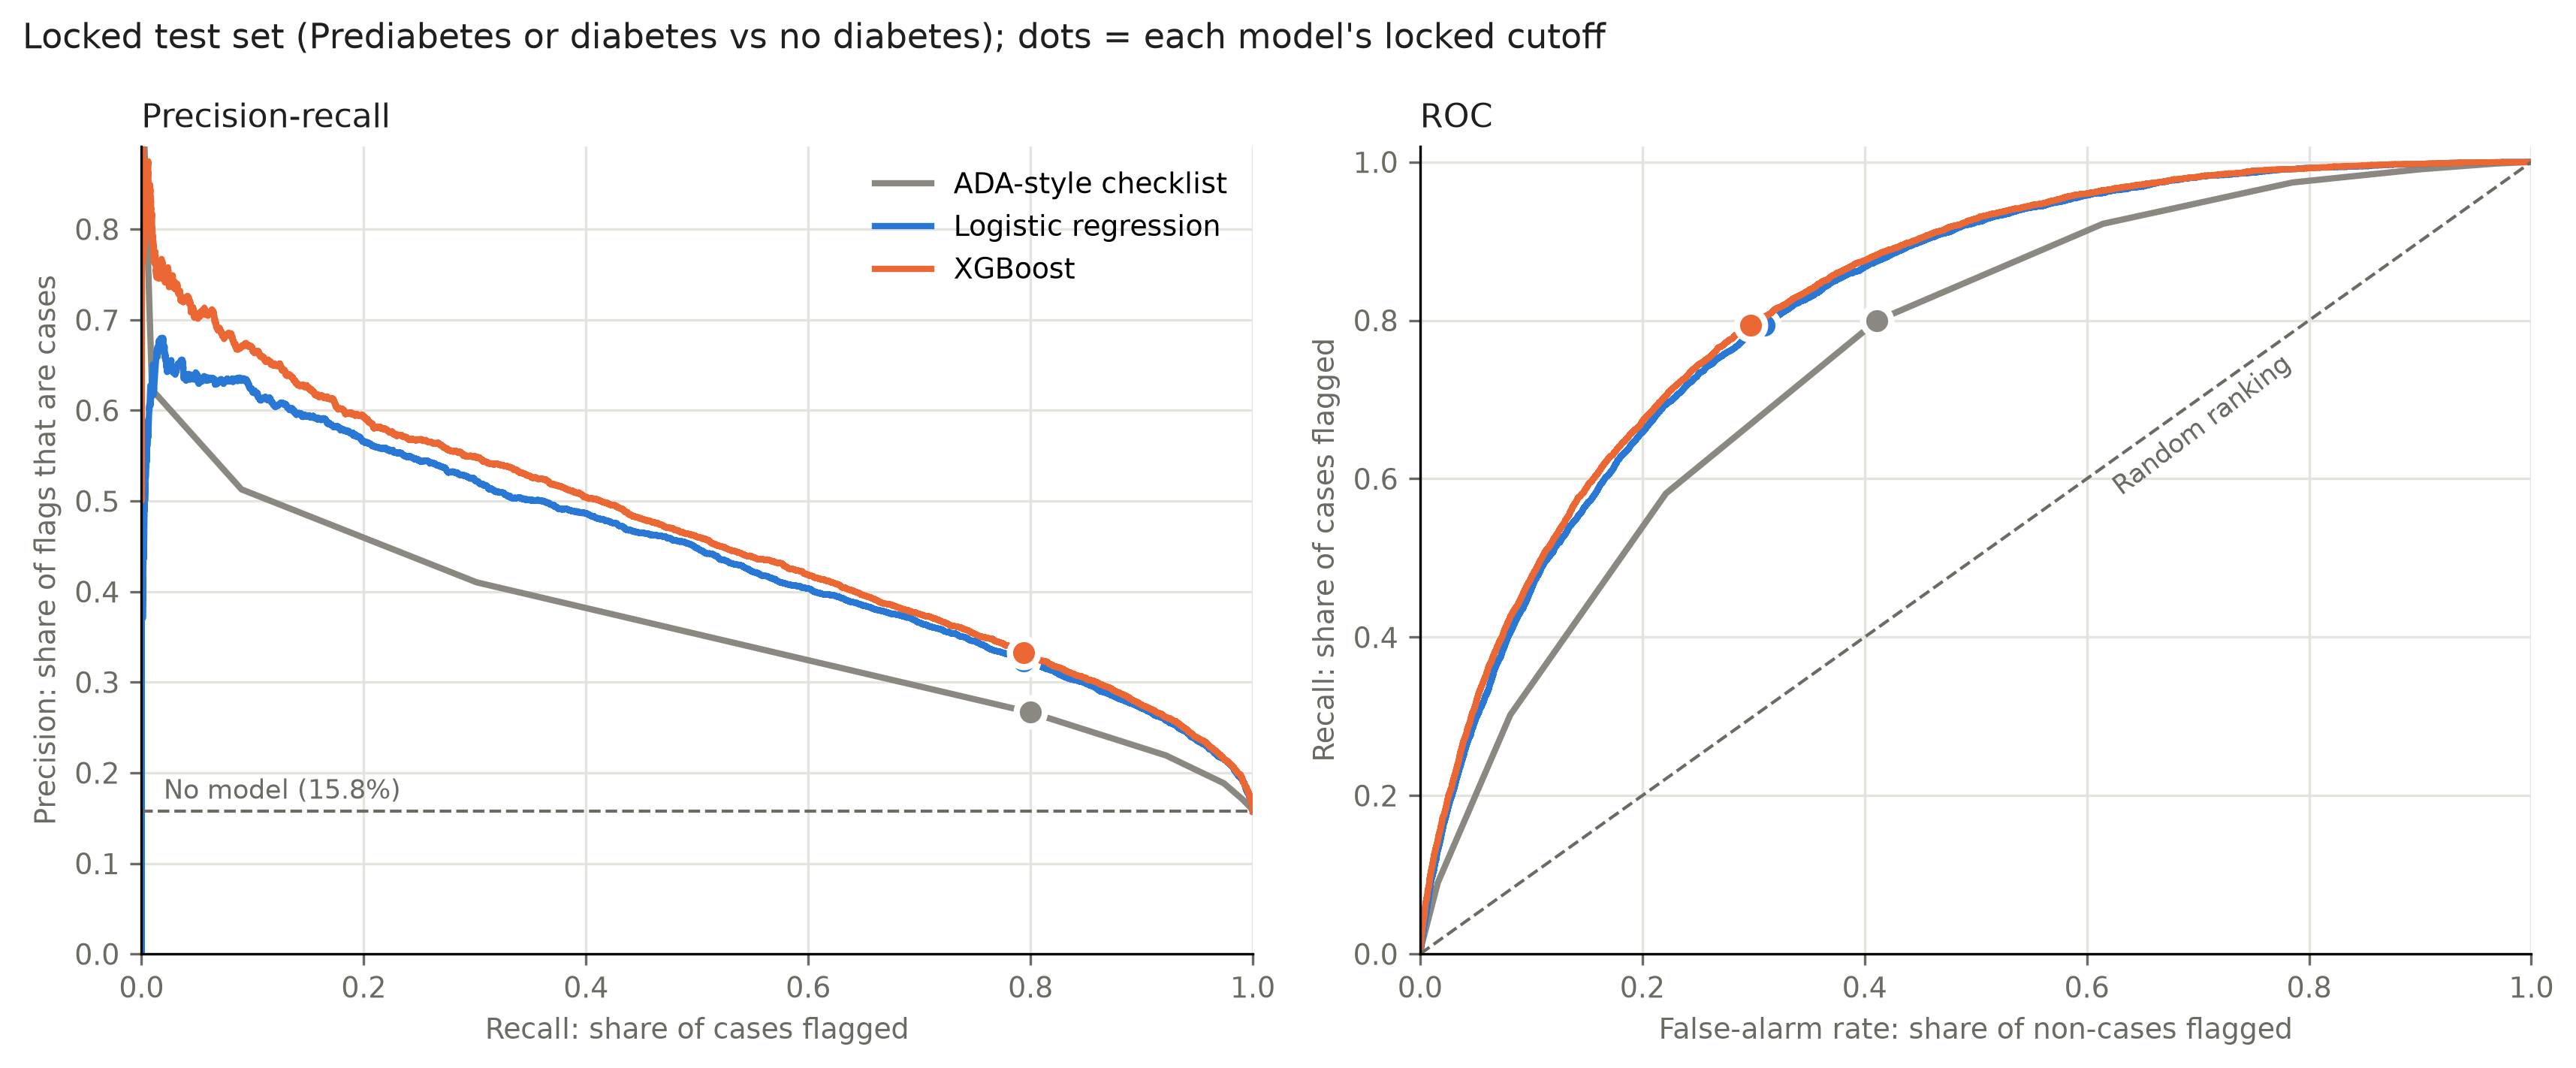

In [6]:
figure(MODELING / "evaluation" / "curves.png")

## Are the predicted risks trustworthy?

In [7]:
pd.read_csv(MODELING / "evaluation" / "calibration_test.csv")

,model,rows,observed_rate,mean_predicted_risk,brier,calibration_intercept,calibration_slope
0,xgboost,50736,0.158,0.157,0.105,0.002,0.991
1,logistic_regression,50736,0.158,0.158,0.107,-0.004,0.994


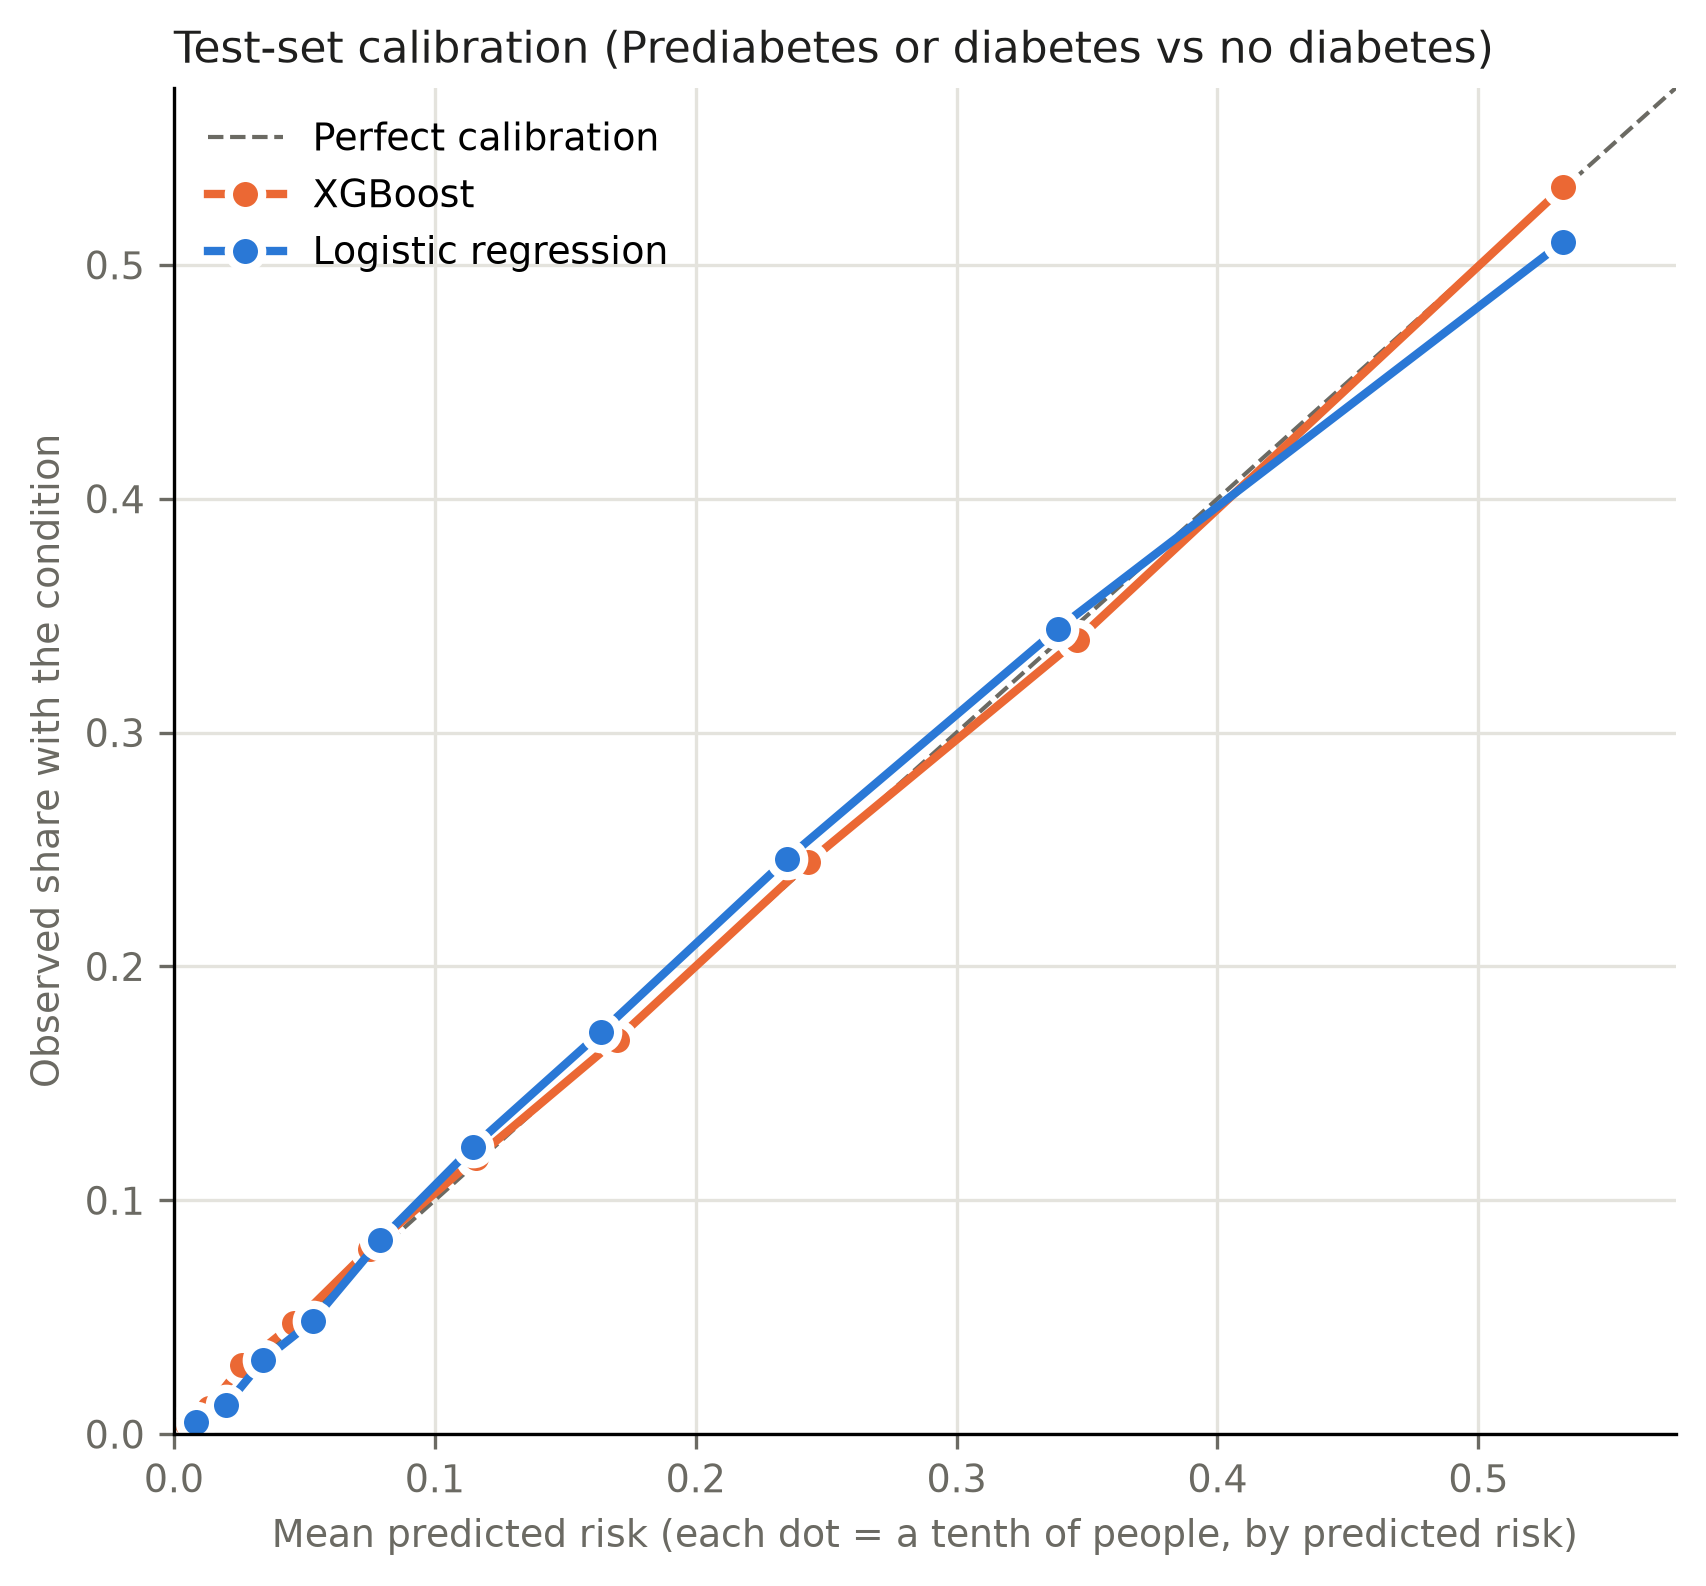

In [8]:
figure(MODELING / "evaluation" / "calibration_test.png", width=560)

## Who does the model serve less well?

In [9]:
pd.read_csv(MODELING / "evaluation" / "subgroups.csv")[
    ["group", "level", "rows", "positives", "recall", "recall_ci_low", "recall_ci_high", "false_positive_rate"]]

,group,level,rows,positives,recall,recall_ci_low,recall_ci_high,false_positive_rate
0,Age,18-44,10914,517,0.437,0.395,0.480,0.061
1,Age,45-64,22230,3453,0.763,0.748,0.776,0.275
2,Age,65+,17592,4025,0.866,0.855,0.876,0.510
3,Sex,Female,28192,4172,0.794,0.781,0.806,0.269
4,Sex,Male,22544,3823,0.794,0.780,0.806,0.335
5,Income,Under $25k,11552,2988,0.894,0.882,0.904,0.512
6,Income,$25k-$50k,12458,2158,0.811,0.794,0.827,0.373
7,Income,$50k+,26726,2849,0.676,0.659,0.693,0.188


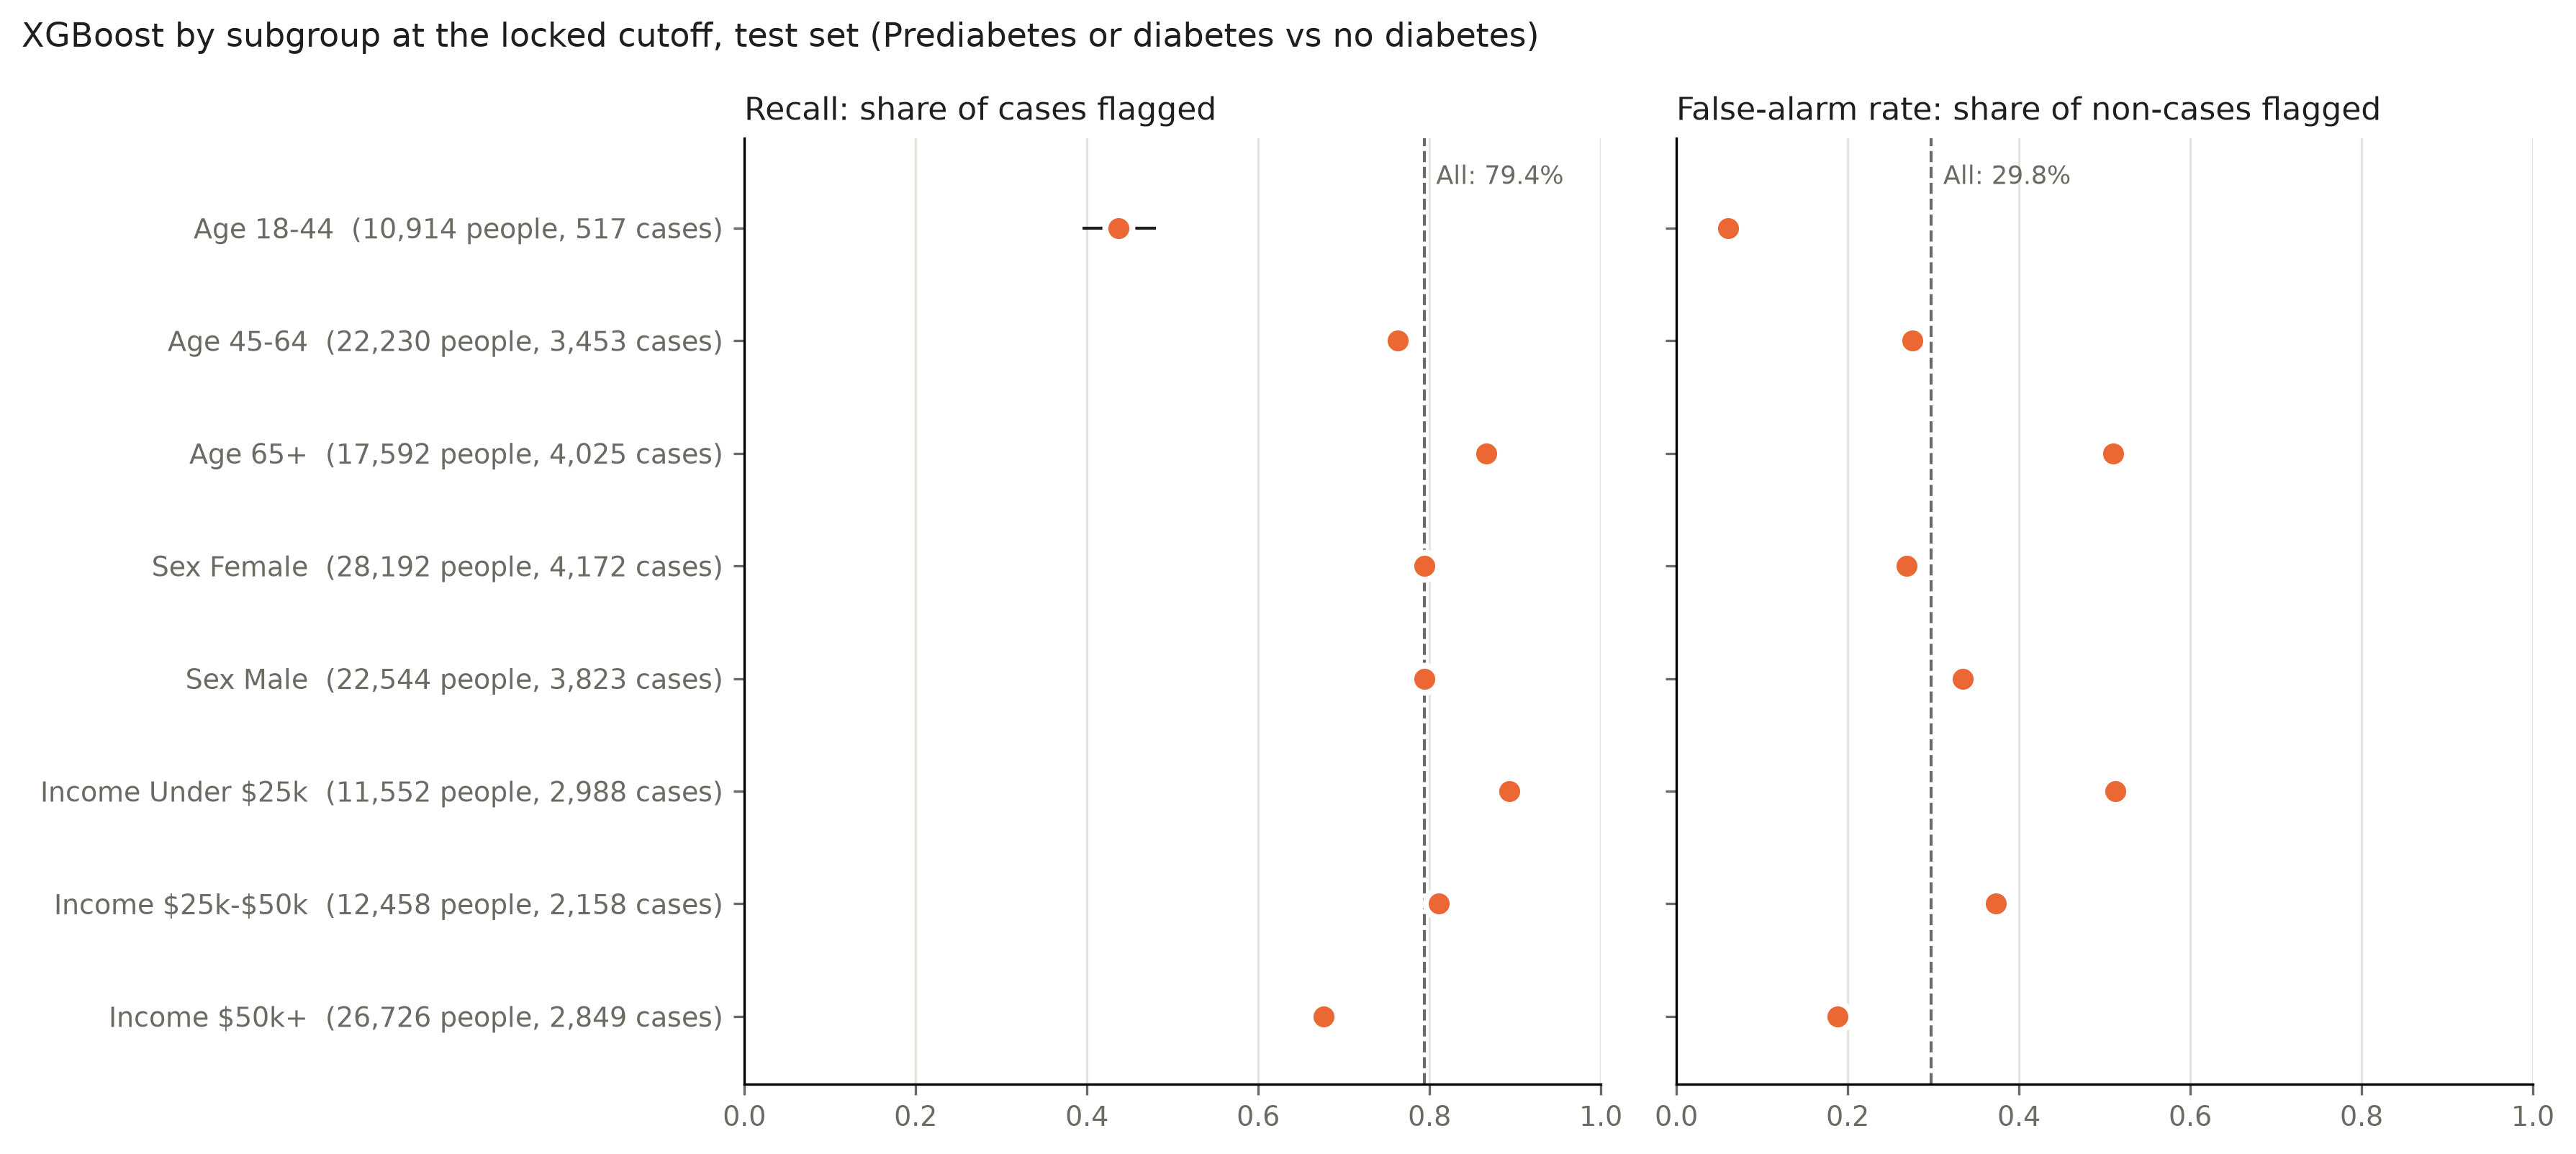

In [10]:
figure(MODELING / "evaluation" / "subgroups.png")

## Who gets missed

In [11]:
pd.read_csv(MODELING / "evaluation" / "missed_cases.csv").set_index("answer")

,caught_cases,missed_cases,non_cases
answer,,,
People,6346.000,1649.000,42741.000
Predicted risk (mean),0.395,0.087,0.125
BMI (mean),32.832,27.530,27.726
"Obese, BMI 30+ (share)",0.647,0.292,0.302
General health fair or poor (share),0.477,0.092,0.134
Age under 45 (share),0.036,0.176,0.243
Age 65+ (share),0.549,0.326,0.317
High blood pressure (share),0.833,0.375,0.371
High cholesterol (share),0.736,0.400,0.379


In [12]:
by_class = MODELING / "evaluation" / "flagged_by_original_class.csv"
pd.read_csv(by_class) if by_class.exists() else "Run `test` with --source to split misses by original class."

,original_class,label,rows,flagged,not_flagged,flagged_share,flagged_share_ci_low,flagged_share_ci_high
0,0,No diabetes,42741,12721,30020,0.298,0.293,0.302
1,1,Prediabetes,906,586,320,0.647,0.615,0.677
2,2,Diabetes,7089,5760,1329,0.813,0.803,0.821


## Scoring two made-up people

The committed pipeline and the locked cutoff are all a screening tool would need.

In [13]:
from diabetes_screening.modeling.cohort import FEATURES
from diabetes_screening.modeling.training_workflow import load_pipeline

pipeline = load_pipeline(MODELING / "training" / "models" / threshold["model_file"])
base = {name: 0 for name in FEATURES} | {"CholCheck": 1, "AnyHealthcare": 1, "PhysActivity": 1}
people = pd.DataFrame([
    base | {"BMI": 24, "GenHlth": 2, "Age": 4, "Education": 6, "Income": 8},
    base | {"BMI": 34, "GenHlth": 4, "Age": 10, "Education": 4, "Income": 4, "HighBP": 1, "HighChol": 1,
            "DiffWalk": 1, "PhysActivity": 0},
], index=["Age 35-39, BMI 24, very good health", "Age 65-69, BMI 34, fair health, high BP and cholesterol"])[FEATURES]
risk = pipeline.predict_proba(people)[:, 1]
pd.DataFrame({"predicted risk": risk.round(3), "flagged": risk >= threshold["threshold"]}, index=people.index)

,predicted risk,flagged
"Age 35-39, BMI 24, very good health",0.010,False
"Age 65-69, BMI 34, fair health, high BP and cholesterol",0.604,True


**Takeaway.** See [evaluation](../docs/evaluation.md) for the full discussion, including the false negatives and the prediabetes-only results. This is a research prototype for risk stratification, not a diagnostic or clinical decision tool. The outcome is self-reported, the data are cross-sectional and unweighted, and associations are not causes.